In [1]:
!pip install osmnx==1.9.3 geopandas --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 9.0 MB/s eta 0:00:00


In [2]:
import numpy as np
import random

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

In [3]:
import osmnx as ox
import networkx as nx
import pandas as pd
import numpy as np
import os
from pyproj import Geod, Transformer
import matplotlib.pyplot as plt

ox.settings.log_console = True
ox.settings.use_cache = True

geod = Geod(ellps="WGS84")

print("OSMnx version:", ox.__version__)

OSMnx version: 1.9.3


In [4]:
COLLEGE_NAME = "Indian Institute of Information Technology, Dharwad"
CENTER_LAT   = 15.3926
CENTER_LON   = 75.0254
RADIUS_M     = 13_000
NETWORK_TYPE = "drive"
CRS_LOCK     = "EPSG:32643"

center_point = (CENTER_LAT, CENTER_LON)

print(f"Outpost: {COLLEGE_NAME}")
print(f"Center point (lat/lon): {center_point}")
print(f"Search radius: {RADIUS_M/1000} km")
print(f"CRS locked: {CRS_LOCK} (UTM 43N, meters)")

Outpost: Indian Institute of Information Technology, Dharwad
Center point (lat/lon): (15.3926, 75.0254)
Search radius: 13.0 km
CRS locked: EPSG:32643 (UTM 43N, meters)


In [5]:
G = ox.graph_from_point(
    center_point,
    dist=RADIUS_M,
    dist_type="bbox",
    network_type=NETWORK_TYPE,
    simplify=True
)

G = ox.project_graph(G, to_crs=CRS_LOCK)

print("Graph pulled successfully.")
print(f"Nodes: {len(G.nodes)}")
print(f"Edges: {len(G.edges)}")

Graph pulled successfully.
Nodes: 21078
Edges: 58476


In [6]:
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)
bbox_west, bbox_south, bbox_east, bbox_north = nodes_gdf.total_bounds

print("Bounding box (locked):")
print(f"  North: {bbox_north}")
print(f"  South: {bbox_south}")
print(f"  East:  {bbox_east}")
print(f"  West:  {bbox_west}")

Bounding box (locked):
  North: 1714671.1447481143
  South: 1688824.4216401712
  East:  515741.00797379913
  West:  489811.1311850927


In [7]:
output_dir = "/content/recon_survey"
os.makedirs(output_dir, exist_ok=True)

graphml_path = os.path.join(output_dir, "hubli_dharwad.graphml")
ox.save_graphml(G, filepath=graphml_path)

city_record = {
    "city_name": ["Hubli-Dharwad"],
    "reference_point_name": [COLLEGE_NAME],
    "reference_lat": [CENTER_LAT],
    "reference_lon": [CENTER_LON],
    "search_radius_km": [RADIUS_M / 1000],
    "crs": [CRS_LOCK],
    "bbox_north": [bbox_north],
    "bbox_south": [bbox_south],
    "bbox_east": [bbox_east],
    "bbox_west": [bbox_west],
    "node_count": [len(G.nodes)],
    "edge_count": [len(G.edges)],
    "network_type": [NETWORK_TYPE],
    "graphml_file": ["hubli_dharwad.graphml"],
}
city_df = pd.DataFrame(city_record)

city_csv_path = os.path.join(output_dir, "city.csv")
city_df.to_csv(city_csv_path, index=False)

city_df

,city_name,reference_point_name,reference_lat,reference_lon,search_radius_km,crs,bbox_north,bbox_south,bbox_east,bbox_west,node_count,edge_count,network_type,graphml_file
0,Hubli-Dharwad,"Indian Institute of Information Technology, Dh...",15.3926,75.0254,13.0,EPSG:32643,1.714671e+06,1.688824e+06,515741.007974,489811.131185,21078,58476,drive,hubli_dharwad.graphml


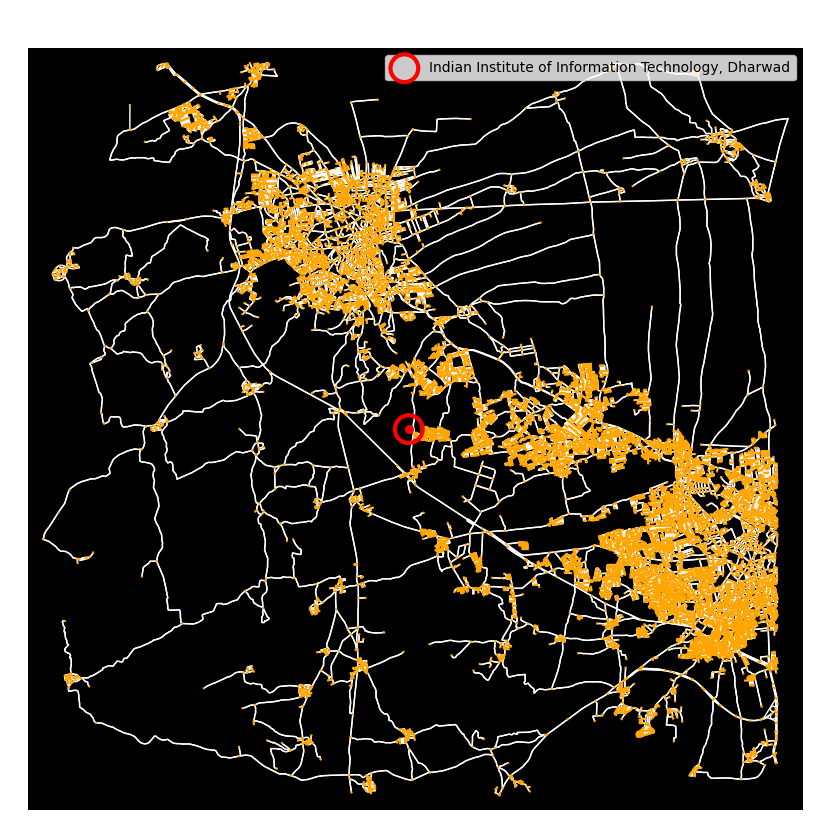

In [8]:
transformer = Transformer.from_crs("EPSG:4326", CRS_LOCK, always_xy=True)
college_x, college_y = transformer.transform(CENTER_LON, CENTER_LAT)

fig, ax = ox.plot_graph(
    G, node_size=3, node_color="orange", edge_color="white",
    bgcolor="black", figsize=(10, 10), show=False, close=False
)

ax.scatter(college_x, college_y, s=400, facecolors='none', edgecolors='red',
           linewidths=3, zorder=5, label=COLLEGE_NAME)
ax.scatter(college_x, college_y, s=30, color='red', zorder=6)

ax.set_title(f"Recon Survey: {COLLEGE_NAME} — 13 km radius", color="white", fontsize=14)
ax.legend(loc='upper right', fontsize=10)
plt.show()

In [9]:
city_row = pd.read_csv(os.path.join(output_dir, "city.csv")).iloc[0]
CENTER_LAT = city_row["reference_lat"]
CENTER_LON = city_row["reference_lon"]
RADIUS_KM  = city_row["search_radius_km"]
RADIUS_M   = RADIUS_KM * 1000

print(f"Loaded center: ({CENTER_LAT}, {CENTER_LON}), radius: {RADIUS_KM} km")

Loaded center: (15.3926, 75.0254), radius: 13.0 km


In [10]:
# Approximate coordinates for named areas — EDIT these if you know more precise ones,
# especially Sattur, Iskcon, and the "Beside X" locations.
known_places = {
    "Dharwad":         (15.4589, 75.0078),
    "Hubli":           (15.3647, 75.1240),
    "Sattur":          (15.3400, 75.1300),
    "Airport":         (15.3617, 75.0849),
    "Iskcon":          (15.3550, 75.1180),
    "Beside Airport":  (15.3700, 75.0900),
    "Beside Highway":  (15.4000, 75.0600),
    "Beside Dharwad":  (15.4300, 75.0200),
}

print(f"Reference center (IIIT Dharwad): ({CENTER_LAT}, {CENTER_LON})\n")

place_bearings = {}
for name, (plat, plon) in known_places.items():
    fwd_bearing, _, dist_m = geod.inv(CENTER_LON, CENTER_LAT, plon, plat)
    bearing_360 = fwd_bearing % 360
    place_bearings[name] = bearing_360
    print(f"{name:20s} bearing={bearing_360:6.1f}°  distance={dist_m/1000:6.2f} km")

Reference center (IIIT Dharwad): (15.3926, 75.0254)

Dharwad              bearing= 345.6°  distance=  7.58 km
Hubli                bearing= 106.2°  distance= 11.03 km
Sattur               bearing= 117.4°  distance= 12.65 km
Airport              bearing= 118.2°  distance=  7.25 km
Iskcon               bearing= 112.7°  distance= 10.78 km
Beside Airport       bearing= 109.8°  distance=  7.37 km
Beside Highway       bearing=  77.6°  distance=  3.80 km
Beside Dharwad       bearing= 352.0°  distance=  4.18 km


In [11]:
N_DISTRICTS = 8
SECTOR_ANGLE = 360 / N_DISTRICTS
CENTROID_RADIUS_M = RADIUS_M * 0.316  # tuned so avg inter-zone chord ~5.9km (was RADIUS_M/2 = 6.5km, avg ~9.3km)

compass_names = ["North", "Northeast", "East", "Southeast",
                  "South", "Southwest", "West", "Northwest"]

custom_names = {i + 1: compass_names[i] for i in range(N_DISTRICTS)}

for name, bearing in place_bearings.items():
    sector_index = int(bearing // SECTOR_ANGLE) % N_DISTRICTS
    district_id = sector_index + 1
    custom_names[district_id] = name

print("Corrected district_id -> name mapping:")
for did, name in sorted(custom_names.items()):
    print(f"  District {did}: {name}")

districts = []
for i in range(N_DISTRICTS):
    district_id = i + 1
    start_bearing = i * SECTOR_ANGLE
    end_bearing = (i + 1) * SECTOR_ANGLE
    bisector_bearing = start_bearing + (SECTOR_ANGLE / 2)

    dest_lon, dest_lat, _ = geod.fwd(CENTER_LON, CENTER_LAT, bisector_bearing, CENTROID_RADIUS_M)

    districts.append({
        "district_id": district_id,
        "district_name": custom_names[district_id],
        "compass_direction": compass_names[i],
        "bearing_start_deg": start_bearing,
        "bearing_end_deg": end_bearing,
        "centroid_lat": dest_lat,
        "centroid_lon": dest_lon,
    })

districts_df = pd.DataFrame(districts)
districts_df

Corrected district_id -> name mapping:
  District 1: North
  District 2: Beside Highway
  District 3: Beside Airport
  District 4: Southeast
  District 5: South
  District 6: Southwest
  District 7: West
  District 8: Beside Dharwad


,district_id,district_name,compass_direction,bearing_start_deg,bearing_end_deg,centroid_lat,centroid_lon
0,1,North,North,0.0,45.0,15.426899,75.040046
1,2,Beside Highway,Northeast,45.0,90.0,15.406804,75.060756
2,3,Beside Airport,East,90.0,135.0,15.378390,75.060751
3,4,Southeast,Southeast,135.0,180.0,15.358300,75.040042
4,5,South,South,180.0,225.0,15.358300,75.010758
5,6,Southwest,Southwest,225.0,270.0,15.378390,74.990049
6,7,West,West,270.0,315.0,15.406804,74.990044
7,8,Beside Dharwad,Northwest,315.0,360.0,15.426899,75.010754


In [12]:
rename_map = {
    "Beside Dharwad": "Dharwad",
    "North":           "Sattur",
    "Beside Highway":  "Iskcon",
    "Beside Airport":  "Hubli",
    "Southeast":       "Airport",
    "South":           "Beside Airport",
    "Southwest":       "Beside Highway",
    "West":            "Beside Dharwad",
}

districts_df["district_name"] = districts_df["district_name"].replace(rename_map)

print("Corrected names:")
districts_df[["district_id", "district_name", "compass_direction"]]

Corrected names:


,district_id,district_name,compass_direction
0,1,Sattur,North
1,2,Iskcon,Northeast
2,3,Hubli,East
3,4,Airport,Southeast
4,5,Beside Airport,South
5,6,Beside Highway,Southwest
6,7,Beside Dharwad,West
7,8,Dharwad,Northwest


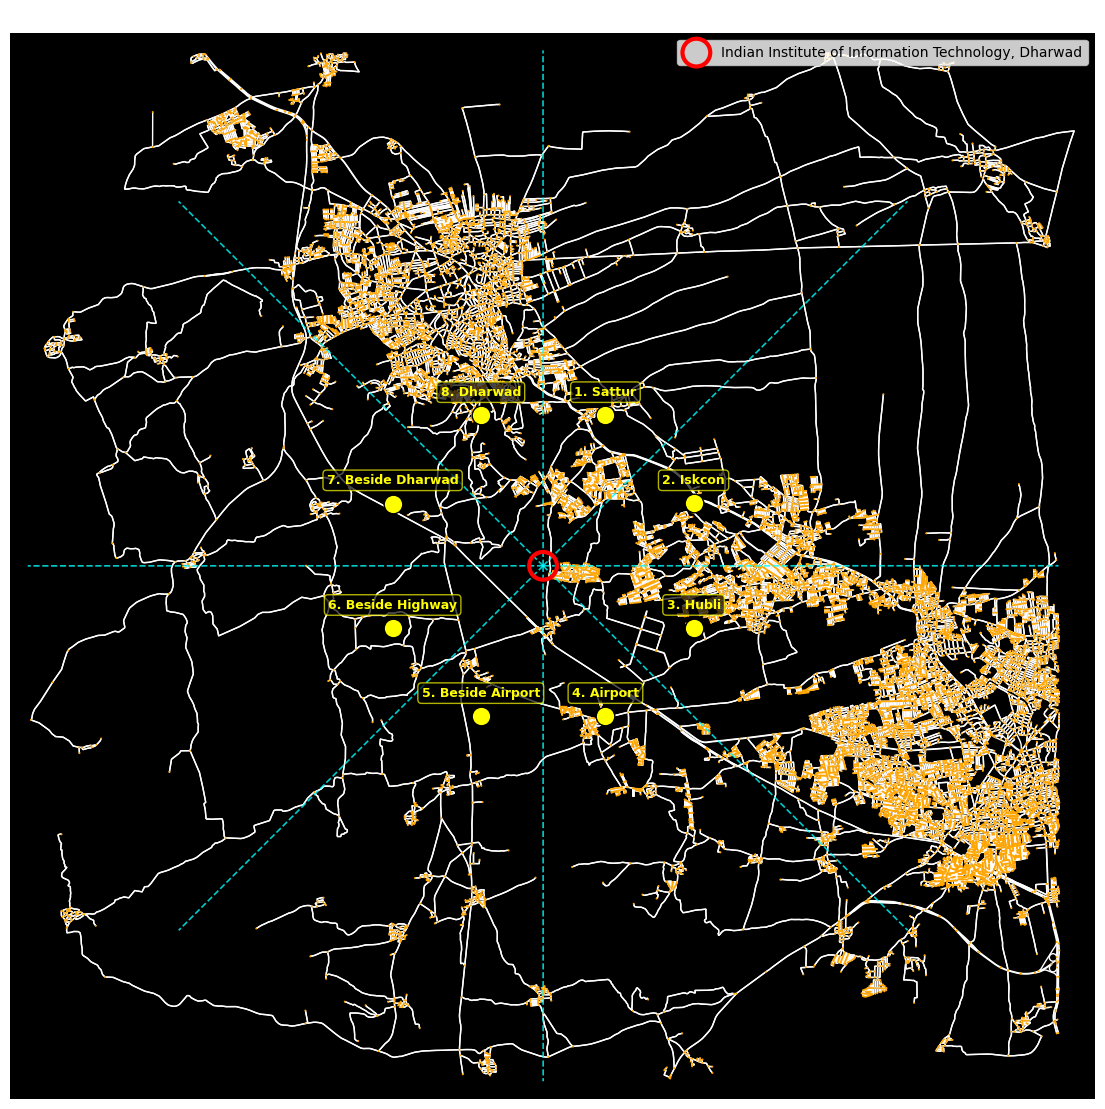

In [13]:
graphml_path = os.path.join(output_dir, "hubli_dharwad.graphml")
G = ox.load_graphml(graphml_path)

transformer = Transformer.from_crs("EPSG:4326", CRS_LOCK, always_xy=True)
college_x, college_y = transformer.transform(CENTER_LON, CENTER_LAT)

fig, ax = ox.plot_graph(G, node_size=2, node_color="orange", edge_color="white",
                          bgcolor="black", figsize=(14, 14), show=False, close=False)

for i in range(N_DISTRICTS):
    bearing = i * SECTOR_ANGLE
    dest_lon, dest_lat, _ = geod.fwd(CENTER_LON, CENTER_LAT, bearing, RADIUS_M)
    ex, ey = transformer.transform(dest_lon, dest_lat)
    ax.plot([college_x, ex], [college_y, ey], color='cyan', linewidth=1.2,
            linestyle='--', zorder=4, alpha=0.8)

for _, row in districts_df.iterrows():
    dx, dy = transformer.transform(row["centroid_lon"], row["centroid_lat"])
    ax.scatter(dx, dy, s=180, color='yellow', edgecolors='black', zorder=6)
    ax.annotate(f"{row['district_id']}. {row['district_name']}", (dx, dy),
                color='yellow', fontsize=9, fontweight='bold', ha='center', va='bottom',
                xytext=(0, 12), textcoords='offset points', zorder=7,
                bbox=dict(boxstyle="round,pad=0.3", facecolor='black', edgecolor='yellow', alpha=0.7))

ax.scatter(college_x, college_y, s=400, facecolors='none', edgecolors='red',
           linewidths=3, zorder=6, label=COLLEGE_NAME)
ax.set_title(f"13 km Radius — 8 Districts — {COLLEGE_NAME}", color="white", fontsize=14)
ax.legend(loc='upper right', fontsize=10)
plt.show()

In [14]:
demand_weights_by_name = {
    "Dharwad":         0.33,
    "Hubli":           0.39,
    "Sattur":          0.10,
    "Airport":         0.03,
    "Iskcon":          0.11,
    "Beside Airport":  0.04 / 3,
    "Beside Highway":  0.04 / 3,
    "Beside Dharwad":  0.04 / 3,
}

weight_check = sum(demand_weights_by_name.values())
print(f"Sum of weights: {weight_check:.6f}")
assert abs(weight_check - 1.0) < 1e-6, "Weights must sum to 1.0"

districts_df["demand_weight"] = districts_df["district_name"].map(demand_weights_by_name)

print(f"Total demand_weight: {districts_df['demand_weight'].sum():.6f}")
districts_df[["district_id", "district_name", "demand_weight"]]


Sum of weights: 1.000000
Total demand_weight: 1.000000


,district_id,district_name,demand_weight
0,1,Sattur,0.100000
1,2,Iskcon,0.110000
2,3,Hubli,0.390000
3,4,Airport,0.030000
4,5,Beside Airport,0.013333
5,6,Beside Highway,0.013333
6,7,Beside Dharwad,0.013333
7,8,Dharwad,0.330000


In [15]:
total_area_km2 = np.pi * (RADIUS_KM ** 2)
area_per_district_km2 = total_area_km2 / N_DISTRICTS

districts_df["area_km2"] = area_per_district_km2

print(f"Total recon area: {total_area_km2:.2f} km²")
print(f"Area per district: {area_per_district_km2:.2f} km²")
districts_df

Total recon area: 530.93 km²
Area per district: 66.37 km²


,district_id,district_name,compass_direction,bearing_start_deg,bearing_end_deg,centroid_lat,centroid_lon,demand_weight,area_km2
0,1,Sattur,North,0.0,45.0,15.426899,75.040046,0.100000,66.366145
1,2,Iskcon,Northeast,45.0,90.0,15.406804,75.060756,0.110000,66.366145
2,3,Hubli,East,90.0,135.0,15.378390,75.060751,0.390000,66.366145
3,4,Airport,Southeast,135.0,180.0,15.358300,75.040042,0.030000,66.366145
4,5,Beside Airport,South,180.0,225.0,15.358300,75.010758,0.013333,66.366145
5,6,Beside Highway,Southwest,225.0,270.0,15.378390,74.990049,0.013333,66.366145
6,7,Beside Dharwad,West,270.0,315.0,15.406804,74.990044,0.013333,66.366145
7,8,Dharwad,Northwest,315.0,360.0,15.426899,75.010754,0.330000,66.366145


In [16]:
districts_csv_path = os.path.join(output_dir, "districts.csv")
districts_df.to_csv(districts_csv_path, index=False)

print(f"Saved to: {districts_csv_path}")
districts_df

Saved to: /content/recon_survey/districts.csv


,district_id,district_name,compass_direction,bearing_start_deg,bearing_end_deg,centroid_lat,centroid_lon,demand_weight,area_km2
0,1,Sattur,North,0.0,45.0,15.426899,75.040046,0.100000,66.366145
1,2,Iskcon,Northeast,45.0,90.0,15.406804,75.060756,0.110000,66.366145
2,3,Hubli,East,90.0,135.0,15.378390,75.060751,0.390000,66.366145
3,4,Airport,Southeast,135.0,180.0,15.358300,75.040042,0.030000,66.366145
4,5,Beside Airport,South,180.0,225.0,15.358300,75.010758,0.013333,66.366145
5,6,Beside Highway,Southwest,225.0,270.0,15.378390,74.990049,0.013333,66.366145
6,7,Beside Dharwad,West,270.0,315.0,15.406804,74.990044,0.013333,66.366145
7,8,Dharwad,Northwest,315.0,360.0,15.426899,75.010754,0.330000,66.366145


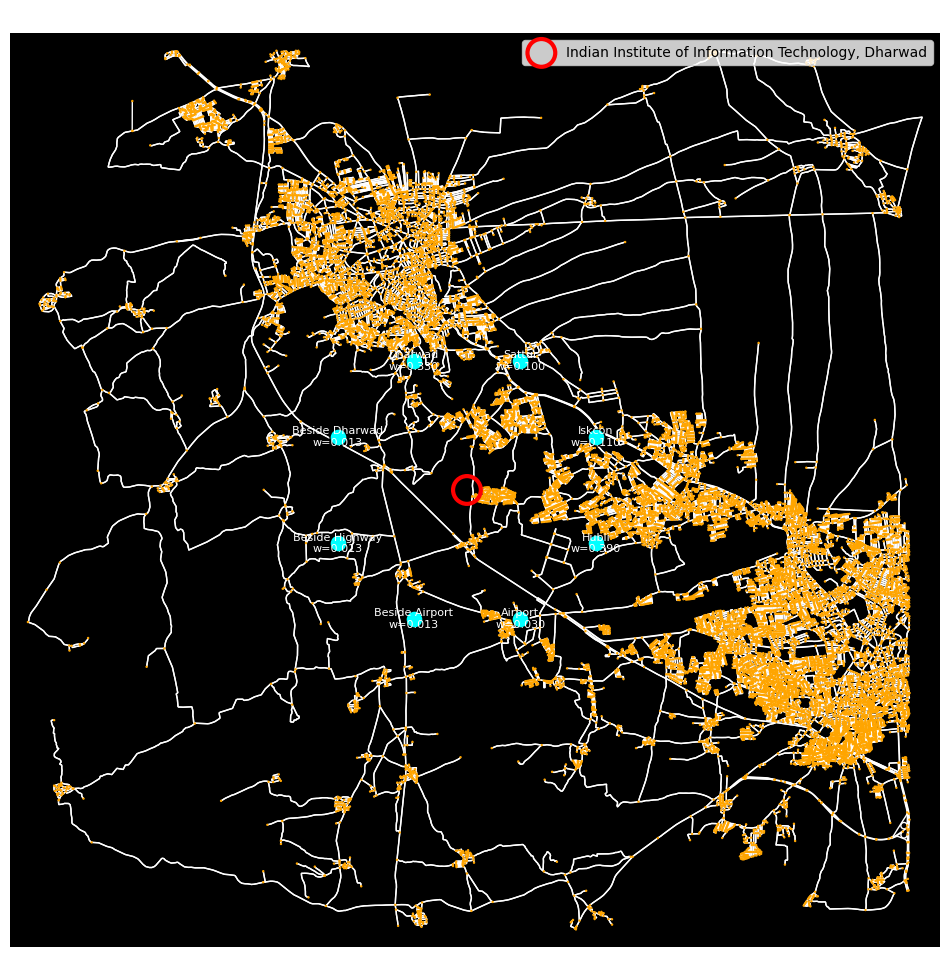

In [17]:
fig, ax = ox.plot_graph(
    G, node_size=3, node_color="orange", edge_color="white",
    bgcolor="black", figsize=(12, 12), show=False, close=False
)

ax.scatter(college_x, college_y, s=400, facecolors='none', edgecolors='red',
           linewidths=3, zorder=5, label=COLLEGE_NAME)

for _, row in districts_df.iterrows():
    dx, dy = transformer.transform(row["centroid_lon"], row["centroid_lat"])
    ax.scatter(dx, dy, s=150, color='cyan', edgecolors='black', zorder=6)
    ax.annotate(
        f"{row['district_name']}\nw={row['demand_weight']:.3f}",
        (dx, dy), color='white', fontsize=8,
        ha='center', va='center', zorder=7
    )

ax.set_title(f"Final Districts — {COLLEGE_NAME}", color="white", fontsize=14)
ax.legend(loc='upper right', fontsize=10)
plt.show()

In [18]:
np.random.seed(42)

districts_csv_path = os.path.join(output_dir, "districts.csv")
districts_df = pd.read_csv(districts_csv_path)

print(f"Loaded {len(districts_df)} zones")
districts_df[["district_id", "district_name", "demand_weight"]]

Loaded 8 zones


,district_id,district_name,demand_weight
0,1,Sattur,0.100000
1,2,Iskcon,0.110000
2,3,Hubli,0.390000
3,4,Airport,0.030000
4,5,Beside Airport,0.013333
5,6,Beside Highway,0.013333
6,7,Beside Dharwad,0.013333
7,8,Dharwad,0.330000


In [19]:
small_restaurants = pd.DataFrame({
    "restaurant_id": [f"R-S-{i+1:03d}" for i in range(67)],
    "size_tier": "small",
})
print(f"Small restaurants registered: {len(small_restaurants)}")
small_restaurants.head()


Small restaurants registered: 67


,restaurant_id,size_tier
0,R-S-001,small
1,R-S-002,small
2,R-S-003,small
3,R-S-004,small
4,R-S-005,small


In [20]:
medium_restaurants = pd.DataFrame({
    "restaurant_id": [f"R-M-{i+1:03d}" for i in range(104)],
    "size_tier": "medium",
})
print(f"Medium restaurants registered: {len(medium_restaurants)}")
medium_restaurants.head()


Medium restaurants registered: 104


,restaurant_id,size_tier
0,R-M-001,medium
1,R-M-002,medium
2,R-M-003,medium
3,R-M-004,medium
4,R-M-005,medium


In [21]:
large_restaurants = pd.DataFrame({
    "restaurant_id": [f"R-L-{i+1:03d}" for i in range(79)],
    "size_tier": "large",
})
print(f"Large restaurants registered: {len(large_restaurants)}")

restaurants_df = pd.concat([small_restaurants, medium_restaurants, large_restaurants], ignore_index=True)

print(f"\nTotal restaurants: {len(restaurants_df)}")
assert len(restaurants_df) == 250, "Restaurant count must equal 250"
restaurants_df["size_tier"].value_counts()


Large restaurants registered: 79

Total restaurants: 250


,count
size_tier,
medium,104
large,79
small,67


In [22]:
zone_ids = districts_df["district_id"].values
zone_weights = districts_df["demand_weight"].values

restaurants_df["zone_id"] = np.random.choice(zone_ids, size=len(restaurants_df), p=zone_weights)

zone_name_lookup = districts_df.set_index("district_id")["district_name"]
restaurants_df["zone_name"] = restaurants_df["zone_id"].map(zone_name_lookup)

print("Restaurant count per zone:")
print(restaurants_df.groupby(["zone_id", "zone_name"]).size().sort_values(ascending=False))


Restaurant count per zone:
zone_id  zone_name     
3        Hubli             91
8        Dharwad           80
2        Iskcon            29
1        Sattur            28
5        Beside Airport     8
4        Airport            6
6        Beside Highway     4
7        Beside Dharwad     4
dtype: int64


In [23]:
prep_time_ranges = {
    "small":  (10, 15),
    "medium": (15, 25),
    "large":  (20, 30),
}

def assign_prep_time(tier):
    low, high = prep_time_ranges[tier]
    return np.random.randint(low, high + 1)

restaurants_df["prep_time_min"] = restaurants_df["size_tier"].apply(assign_prep_time)

print("Prep time summary by tier:")
restaurants_df.groupby("size_tier")["prep_time_min"].agg(["min", "max", "mean"])


Prep time summary by tier:


,min,max,mean
size_tier,,,
large,20,30,25.164557
medium,15,25,19.625000
small,10,15,12.328358


In [24]:
restaurants_df = restaurants_df[["restaurant_id", "size_tier", "zone_id", "zone_name", "prep_time_min"]]

restaurants_csv_path = os.path.join(output_dir, "restaurants.csv")
restaurants_df.to_csv(restaurants_csv_path, index=False)

print(f"Saved to: {restaurants_csv_path}")
print(f"Total restaurants: {len(restaurants_df)}")
restaurants_df


Saved to: /content/recon_survey/restaurants.csv
Total restaurants: 250


,restaurant_id,size_tier,zone_id,zone_name,prep_time_min
0,R-S-001,small,3,Hubli,14
1,R-S-002,small,8,Dharwad,14
2,R-S-003,small,8,Dharwad,10
3,R-S-004,small,3,Hubli,12
4,R-S-005,small,2,Iskcon,11
...,...,...,...,...,...
245,R-L-075,large,8,Dharwad,29
246,R-L-076,large,3,Hubli,20
247,R-L-077,large,8,Dharwad,25
248,R-L-078,large,8,Dharwad,26


In [25]:
expected_pct = {
    "Dharwad": 33, "Hubli": 40, "Sattur": 8, "Airport": 6, "Iskcon": 8,
    "Beside Airport": 5/3, "Beside Highway": 5/3, "Beside Dharwad": 5/3
}

actual_counts = restaurants_df["zone_name"].value_counts()
actual_pct = (actual_counts / len(restaurants_df) * 100).round(1)

comparison = pd.DataFrame({
    "expected_%": pd.Series(expected_pct).round(1),
    "actual_%": actual_pct
}).fillna(0)

print(comparison)
print(f"\nTotal restaurants: {len(restaurants_df)} (expected 250)")

assert len(restaurants_df) == 250
assert (restaurants_df["size_tier"] == "small").sum() == 67
assert (restaurants_df["size_tier"] == "medium").sum() == 104
assert (restaurants_df["size_tier"] == "large").sum() == 79

for tier, (low, high) in prep_time_ranges.items():
    tier_data = restaurants_df[restaurants_df["size_tier"] == tier]["prep_time_min"]
    within_bounds = tier_data.between(low, high).all()
    print(f"{tier}: prep_time within [{low},{high}]? {within_bounds}")

print("\n✅ All checks passed.")


                expected_%  actual_%
Airport                6.0       2.4
Beside Airport         1.7       3.2
Beside Dharwad         1.7       1.6
Beside Highway         1.7       1.6
Dharwad               33.0      32.0
Hubli                 40.0      36.4
Iskcon                 8.0      11.6
Sattur                 8.0      11.2

Total restaurants: 250 (expected 250)
small: prep_time within [10,15]? True
medium: prep_time within [15,25]? True
large: prep_time within [20,30]? True

✅ All checks passed.


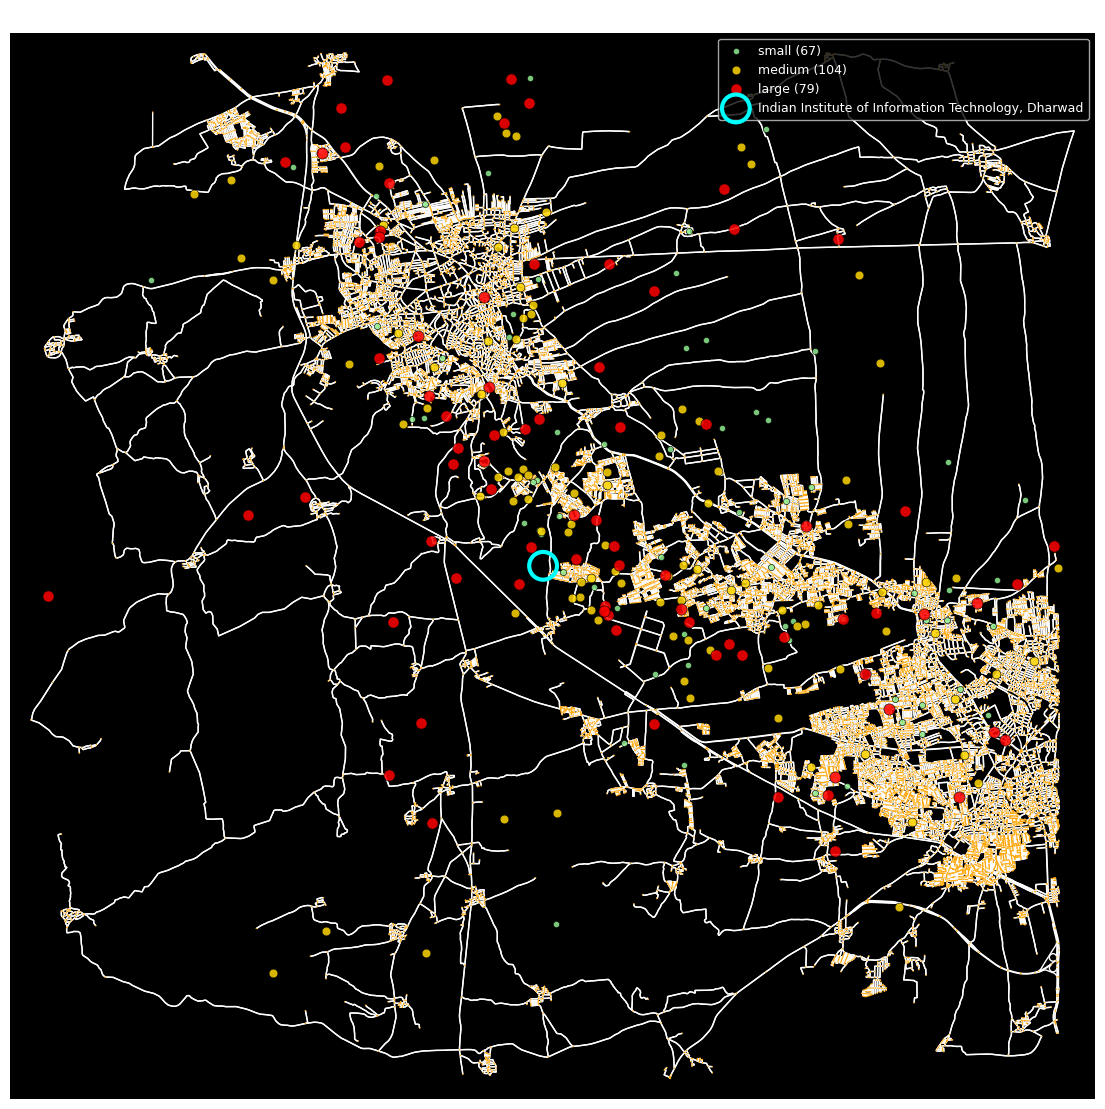

Note: restaurant positions shown are randomly generated for visualization only.
Actual restaurants.csv has no lat/lon — only zone_id, zone_name, size_tier, prep_time_min.


In [26]:
graphml_path = os.path.join(output_dir, "hubli_dharwad.graphml")
G = ox.load_graphml(graphml_path)

transformer = Transformer.from_crs("EPSG:4326", CRS_LOCK, always_xy=True)
college_x, college_y = transformer.transform(CENTER_LON, CENTER_LAT)

np.random.seed(7)  # separate seed for plotting jitter only — doesn't affect restaurants.csv

zone_lookup = districts_df.set_index("district_id")[["bearing_start_deg", "bearing_end_deg", "district_name"]]

plot_lats, plot_lons = [], []
for _, row in restaurants_df.iterrows():
    zone = zone_lookup.loc[row["zone_id"]]
    bearing = np.random.uniform(zone["bearing_start_deg"], zone["bearing_end_deg"])
    dist_m = np.random.uniform(500, RADIUS_M)
    lon, lat, _ = geod.fwd(CENTER_LON, CENTER_LAT, bearing, dist_m)
    plot_lats.append(lat)
    plot_lons.append(lon)

restaurants_plot_x, restaurants_plot_y = transformer.transform(plot_lons, plot_lats)

fig, ax = ox.plot_graph(
    G, node_size=1, node_color="orange", edge_color="white",
    bgcolor="black", figsize=(14, 14), show=False, close=False
)

tier_colors = {"small": "lightgreen", "medium": "gold", "large": "red"}
tier_sizes = {"small": 20, "medium": 40, "large": 65}

for tier, color in tier_colors.items():
    mask = restaurants_df["size_tier"] == tier
    ax.scatter(
        np.array(restaurants_plot_x)[mask], np.array(restaurants_plot_y)[mask],
        s=tier_sizes[tier], color=color, edgecolors='black', linewidths=0.5,
        alpha=0.85, zorder=5, label=f"{tier} ({mask.sum()})"
    )

ax.scatter(college_x, college_y, s=400, facecolors='none', edgecolors='cyan',
           linewidths=3, zorder=6, label=COLLEGE_NAME)

ax.set_title(f"250 Restaurants across 8 Zones — {COLLEGE_NAME}", color="white", fontsize=14)
ax.legend(loc='upper right', fontsize=9, facecolor='black', labelcolor='white')
plt.show()

print("Note: restaurant positions shown are randomly generated for visualization only.")
print("Actual restaurants.csv has no lat/lon — only zone_id, zone_name, size_tier, prep_time_min.")


Day 4

In [27]:
restaurants_csv_path = os.path.join(output_dir, "restaurants.csv")
restaurants_df = pd.read_csv(restaurants_csv_path)

print(f"Loaded {len(restaurants_df)} restaurants")
restaurants_df.head()


Loaded 250 restaurants


,restaurant_id,size_tier,zone_id,zone_name,prep_time_min
0,R-S-001,small,3,Hubli,14
1,R-S-002,small,8,Dharwad,14
2,R-S-003,small,8,Dharwad,10
3,R-S-004,small,3,Hubli,12
4,R-S-005,small,2,Iskcon,11


In [28]:
np.random.seed(11)

# Popularity skew by tier — large restaurants draw more custom, small ones less,
# with randomness within each tier so it's not perfectly uniform
tier_alpha = {"small": 1.0, "medium": 2.0, "large": 3.5}

raw_weights = restaurants_df["size_tier"].map(tier_alpha).apply(
    lambda a: np.random.gamma(shape=a, scale=1.0)
)

restaurants_df["popularity_weight"] = raw_weights / raw_weights.sum()

weight_check = restaurants_df["popularity_weight"].sum()
print(f"Sum of popularity_weight: {weight_check:.6f}")
assert abs(weight_check - 1.0) < 1e-6, "popularity_weight must sum to 1.0"

restaurants_df.groupby("size_tier")["popularity_weight"].agg(["min", "max", "mean", "sum"])


Sum of popularity_weight: 1.000000


,min,max,mean,sum
size_tier,,,,
large,0.000967,0.017521,0.006572,0.519200
medium,0.000076,0.015134,0.003568,0.371021
small,0.000023,0.007685,0.001638,0.109778


In [29]:
PEAK_HOURS  = [12, 13, 19, 20, 21]   # lunch + dinner spike hours
NIGHT_HOURS = [22, 23]                # night window within the 10-24 day

simulation_config = {
    "active_partners_normal": 113,
    "active_partners_peak": 200,
    "active_partners_night": 70,
    "peak_hours": PEAK_HOURS,
    "night_hours": NIGHT_HOURS,
    "max_orders_per_trip": 3,
    "fleet_motorcycle_pct": 1.0,
    "fleet_bike_pct": 0.0,
}

assert abs(simulation_config["fleet_motorcycle_pct"] + simulation_config["fleet_bike_pct"] - 1.0) < 1e-6, \
    "Fleet percentages must sum to 1.0"

import json

config_path = os.path.join(output_dir, "simulation_config.json")
with open(config_path, "w") as f:
    json.dump(simulation_config, f, indent=2)

print(f"Saved to: {config_path}")
print(json.dumps(simulation_config, indent=2))


Saved to: /content/recon_survey/simulation_config.json
{
  "active_partners_normal": 113,
  "active_partners_peak": 200,
  "active_partners_night": 70,
  "peak_hours": [
    12,
    13,
    19,
    20,
    21
  ],
  "night_hours": [
    22,
    23
  ],
  "max_orders_per_trip": 3,
  "fleet_motorcycle_pct": 1.0,
  "fleet_bike_pct": 0.0
}


In [30]:
restaurants_csv_path = os.path.join(output_dir, "restaurants.csv")
restaurants_df.to_csv(restaurants_csv_path, index=False)

print(f"Saved to: {restaurants_csv_path}")
print(f"Total restaurants: {len(restaurants_df)}")
restaurants_df


Saved to: /content/recon_survey/restaurants.csv
Total restaurants: 250


,restaurant_id,size_tier,zone_id,zone_name,prep_time_min,popularity_weight
0,R-S-001,small,3,Hubli,14,0.000354
1,R-S-002,small,8,Dharwad,14,0.000035
2,R-S-003,small,8,Dharwad,10,0.001107
3,R-S-004,small,3,Hubli,12,0.002297
4,R-S-005,small,2,Iskcon,11,0.000970
...,...,...,...,...,...,...
245,R-L-075,large,8,Dharwad,29,0.004313
246,R-L-076,large,3,Hubli,20,0.002638
247,R-L-077,large,8,Dharwad,25,0.008169
248,R-L-078,large,8,Dharwad,26,0.001330


In [31]:
assert "popularity_weight" in restaurants_df.columns
assert abs(restaurants_df["popularity_weight"].sum() - 1.0) < 1e-6
assert len(restaurants_df) == 250, f"Expected 250 restaurants, found {len(restaurants_df)}"

with open(config_path) as f:
    loaded_config = json.load(f)

assert loaded_config["active_partners_normal"] == 113
assert loaded_config["active_partners_peak"] == 200
assert loaded_config["active_partners_night"] == 70
assert loaded_config["max_orders_per_trip"] == 3
assert loaded_config["fleet_motorcycle_pct"] == 1.0
assert loaded_config["fleet_bike_pct"] == 0.0
assert "partners.csv" not in os.listdir(output_dir), "No partners.csv should exist — scouts are a capacity constraint, not entities"

print("✅ All Day 4 checks passed.")
print(f"Files in {output_dir}: {os.listdir(output_dir)}")


✅ All Day 4 checks passed.
Files in /content/recon_survey: ['restaurants.csv', 'city.csv', 'simulation_config.json', 'districts.csv', 'hubli_dharwad.graphml']


Day 5

In [32]:
np.random.seed(21)

districts_df    = pd.read_csv(os.path.join(output_dir, "districts.csv"))
restaurants_df  = pd.read_csv(os.path.join(output_dir, "restaurants.csv"))

ORDER_WINDOW_START_HOUR = 10
ORDER_WINDOW_END_HOUR   = 24   # up to 24:00 (midnight), exclusive upper bound

BASELINE_ORDERS_PER_HOUR = 73

LUNCH_SPIKE_HOURS  = [12, 13]
DINNER_SPIKE_HOURS = [19, 20, 21]
NIGHT_HOURS        = [22, 23]

SPIKE_RATE_LOW  = 165
SPIKE_RATE_HIGH = 200

hours = list(range(ORDER_WINDOW_START_HOUR, ORDER_WINDOW_END_HOUR))

hourly_rate = {}
for h in hours:
    if h in LUNCH_SPIKE_HOURS or h in DINNER_SPIKE_HOURS:
        hourly_rate[h] = int(np.random.randint(SPIKE_RATE_LOW, SPIKE_RATE_HIGH + 1))
    else:
        hourly_rate[h] = BASELINE_ORDERS_PER_HOUR   # offpeak and night hours share the same flat rate

expected_total = sum(hourly_rate.values())

print("Hourly order-rate profile:")
for h, r in hourly_rate.items():
    tag = "LUNCH SPIKE" if h in LUNCH_SPIKE_HOURS else ("DINNER SPIKE" if h in DINNER_SPIKE_HOURS else "")
    print(f"  {h:02d}:00  ->  {r:5d} orders/hr  {tag}")

print(f"\nExpected total orders (sum of hourly rates): {expected_total:.0f}")


Hourly order-rate profile:
  10:00  ->     73 orders/hr  
  11:00  ->     73 orders/hr  
  12:00  ->    174 orders/hr  LUNCH SPIKE
  13:00  ->    180 orders/hr  LUNCH SPIKE
  14:00  ->     73 orders/hr  
  15:00  ->     73 orders/hr  
  16:00  ->     73 orders/hr  
  17:00  ->     73 orders/hr  
  18:00  ->     73 orders/hr  
  19:00  ->    169 orders/hr  DINNER SPIKE
  20:00  ->    200 orders/hr  DINNER SPIKE
  21:00  ->    199 orders/hr  DINNER SPIKE
  22:00  ->     73 orders/hr  
  23:00  ->     73 orders/hr  

Expected total orders (sum of hourly rates): 1579


In [33]:
order_rows = []
order_counter = 1

for h in hours:
    rate = hourly_rate[h]
    n_orders_this_hour = np.random.poisson(rate)

    seconds_in_hour = np.random.randint(0, 3600, size=n_orders_this_hour)
    timestamps = h * 3600 + seconds_in_hour

    for ts in timestamps:
        order_rows.append({
            "order_id": f"O-{order_counter:06d}",
            "timestamp_sec": int(ts),
        })
        order_counter += 1

orders_df = pd.DataFrame(order_rows).sort_values("timestamp_sec").reset_index(drop=True)

print(f"Total orders generated: {len(orders_df)}")
orders_df.head()

Total orders generated: 1515


,order_id,timestamp_sec
0,O-000024,36050
1,O-000006,36233
2,O-000050,36235
3,O-000053,36388
4,O-000002,36447


In [34]:
# restaurant_id: sample restaurants weighted by their popularity_weight
orders_df["restaurant_id"] = np.random.choice(
    restaurants_df["restaurant_id"].values,
    size=len(orders_df),
    p=restaurants_df["popularity_weight"].values
)

# destination_zone_id: mostly same zone as the restaurant (intra-zone, local delivery),
# occasionally a different zone (inter-zone, cross-city delivery) — inter-zone destinations
# are drawn mostly from NEARBY zones (proximity-weighted), reflecting real SLA-bound
# delivery radii rather than allowing long-haul cross-city deliveries at equal odds.
INTRA_ZONE_BIAS = 0.75   # probability an order's destination falls in the same zone as its restaurant

NEAR_ZONE_COUNT = 4      # nearest 4 zones eligible for the bulk of the inter-zone share
NEAR_SHARE      = 0.90   # share of inter-zone orders going to the nearest NEAR_ZONE_COUNT zones
FAR_SHARE       = 0.10   # remaining share going to the farthest zones

restaurant_zone_lookup = restaurants_df.set_index("restaurant_id")["zone_id"]
orders_df["_restaurant_zone_id"] = orders_df["restaurant_id"].map(restaurant_zone_lookup)

is_intra = np.random.random(len(orders_df)) < INTRA_ZONE_BIAS

dest_zone_ids = np.empty(len(orders_df), dtype=int)
dest_zone_ids[is_intra] = orders_df.loc[is_intra, "_restaurant_zone_id"].values

zone_ids_arr = districts_df["district_id"].values
demand_w     = districts_df.set_index("district_id")["demand_weight"]
centroid_lut = districts_df.set_index("district_id")[["centroid_lat", "centroid_lon"]]

def geodesic_km(z1, z2):
    lat1, lon1 = centroid_lut.loc[z1]
    lat2, lon2 = centroid_lut.loc[z2]
    _, _, dist_m = geod.inv(lon1, lat1, lon2, lat2)
    return dist_m / 1000

for rz in orders_df.loc[~is_intra, "_restaurant_zone_id"].unique():
    mask = (~is_intra) & (orders_df["_restaurant_zone_id"] == rz)
    n = mask.sum()

    other_zones = [z for z in zone_ids_arr if z != rz]
    ranked      = sorted(other_zones, key=lambda z: geodesic_km(rz, z))
    near_zones  = ranked[:NEAR_ZONE_COUNT]
    far_zones   = ranked[NEAR_ZONE_COUNT:]

    near_w = demand_w.loc[near_zones]
    near_w = near_w / near_w.sum() * NEAR_SHARE
    far_w  = demand_w.loc[far_zones]
    far_w  = far_w / far_w.sum() * FAR_SHARE

    combined_w = pd.concat([near_w, far_w]).reindex(other_zones)
    dest_zone_ids[mask.values] = np.random.choice(other_zones, size=n, p=combined_w.values)

orders_df["destination_zone_id"] = dest_zone_ids
orders_df = orders_df.drop(columns=["_restaurant_zone_id"])

orders_df = orders_df[["order_id", "timestamp_sec", "restaurant_id", "destination_zone_id"]]

print(f"Intra-zone orders: {is_intra.sum()} ({is_intra.mean()*100:.1f}%)")
print(f"Inter-zone orders: {(~is_intra).sum()} ({(~is_intra).mean()*100:.1f}%)")
print("Orders linked to restaurant_id and destination_zone_id (no delivery lat/lon).")
orders_df.head()

Intra-zone orders: 1129 (74.5%)
Inter-zone orders: 386 (25.5%)
Orders linked to restaurant_id and destination_zone_id (no delivery lat/lon).


,order_id,timestamp_sec,restaurant_id,destination_zone_id
0,O-000024,36050,R-S-040,3
1,O-000006,36233,R-L-059,3
2,O-000050,36235,R-L-068,8
3,O-000053,36388,R-L-053,3
4,O-000002,36447,R-L-010,3


Saved to: /content/recon_survey/orders.csv
Total orders: 1515


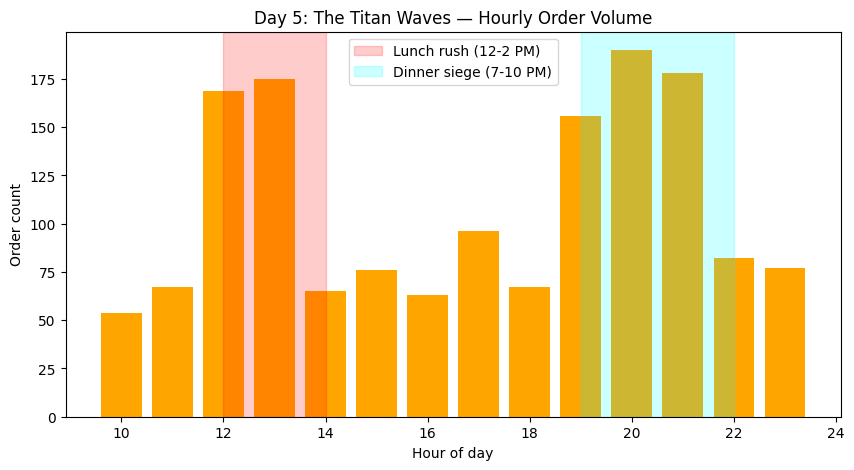

In [35]:
orders_csv_path = os.path.join(output_dir, "orders.csv")
orders_df.to_csv(orders_csv_path, index=False)

print(f"Saved to: {orders_csv_path}")
print(f"Total orders: {len(orders_df)}")

orders_df["hour"] = orders_df["timestamp_sec"] // 3600
hourly_counts = orders_df["hour"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(hourly_counts.index, hourly_counts.values, color="orange")
ax.axvspan(12, 14, color="red", alpha=0.2, label="Lunch rush (12-2 PM)")
ax.axvspan(19, 22, color="cyan", alpha=0.2, label="Dinner siege (7-10 PM)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Order count")
ax.set_title("Day 5: The Titan Waves — Hourly Order Volume")
ax.legend()
plt.show()

orders_df = orders_df.drop(columns=["hour"])

In [36]:
assert "orders.csv" in os.listdir(output_dir)
assert set(orders_df.columns) == {"order_id", "timestamp_sec", "restaurant_id", "destination_zone_id"}
assert orders_df["order_id"].is_unique, "order_id must be unique"

min_ts = ORDER_WINDOW_START_HOUR * 3600
max_ts = ORDER_WINDOW_END_HOUR * 3600
assert orders_df["timestamp_sec"].between(min_ts, max_ts).all(), "timestamps must fall within 10 AM–midnight"

assert orders_df["restaurant_id"].isin(restaurants_df["restaurant_id"]).all()
assert orders_df["destination_zone_id"].isin(districts_df["district_id"]).all()

low_bound  = expected_total * 0.90
high_bound = expected_total * 1.10
total_orders = len(orders_df)
assert low_bound <= total_orders <= high_bound, \
    f"Total orders {total_orders} outside expected range [{low_bound:.0f}, {high_bound:.0f}]"

print(f"✅ All Day 5 checks passed. Total orders: {total_orders}")
print(f"Files in {output_dir}: {os.listdir(output_dir)}")

✅ All Day 5 checks passed. Total orders: 1515
Files in /content/recon_survey: ['restaurants.csv', 'city.csv', 'orders.csv', 'simulation_config.json', 'districts.csv', 'hubli_dharwad.graphml']


Day 6

In [37]:
# ── Day 6: Order Enrichment ─────────────────────────────────────────
np.random.seed(33)

orders_df       = pd.read_csv(os.path.join(output_dir, "orders.csv"))
restaurants_df  = pd.read_csv(os.path.join(output_dir, "restaurants.csv"))
districts_df    = pd.read_csv(os.path.join(output_dir, "districts.csv"))

# prep_time_min comes from the restaurant each order was placed at
prep_time_lookup = restaurants_df.set_index("restaurant_id")["prep_time_min"]
orders_df["prep_time_min"] = orders_df["restaurant_id"].map(prep_time_lookup)

orders_df["estimated_ready_sec"] = orders_df["timestamp_sec"] + orders_df["prep_time_min"] * 60

print("estimated_ready_sec computed.")
orders_df[["order_id", "timestamp_sec", "restaurant_id", "prep_time_min", "estimated_ready_sec"]].head()


estimated_ready_sec computed.


,order_id,timestamp_sec,restaurant_id,prep_time_min,estimated_ready_sec
0,O-000024,36050,R-S-040,13,36830
1,O-000006,36233,R-L-059,26,37793
2,O-000050,36235,R-L-068,22,37555
3,O-000053,36388,R-L-053,28,38068
4,O-000002,36447,R-L-010,28,38127


In [38]:
SLA_WINDOW_SEC = 2100  # fixed SLA window per spec

orders_df["sla_deadline_sec"] = orders_df["timestamp_sec"] + SLA_WINDOW_SEC

print(f"sla_deadline_sec = timestamp_sec + {SLA_WINDOW_SEC}")
orders_df[["order_id", "timestamp_sec", "sla_deadline_sec"]].head()

sla_deadline_sec = timestamp_sec + 2100


,order_id,timestamp_sec,sla_deadline_sec
0,O-000024,36050,38150
1,O-000006,36233,38333
2,O-000050,36235,38335
3,O-000053,36388,38488
4,O-000002,36447,38547


In [39]:
ORDER_VALUE_MEAN_INR = 379
ORDER_VALUE_MIN_INR  = 150

sigma = 0.5
mu = np.log(ORDER_VALUE_MEAN_INR) - (sigma ** 2) / 2

raw_values = np.random.lognormal(mean=mu, sigma=sigma, size=len(orders_df))
orders_df["order_value_inr"] = np.clip(raw_values, ORDER_VALUE_MIN_INR, None).round(2)

print(f"order_value_inr — mean: {orders_df['order_value_inr'].mean():.2f}, "
      f"min: {orders_df['order_value_inr'].min():.2f}, max: {orders_df['order_value_inr'].max():.2f}")
orders_df[["order_id", "order_value_inr"]].head()


order_value_inr — mean: 378.43, min: 150.00, max: 2166.06


,order_id,order_value_inr
0,O-000024,285.18
1,O-000006,150.06
2,O-000050,155.23
3,O-000053,251.47
4,O-000002,300.12


In [40]:
orders_df["hour"] = orders_df["timestamp_sec"] // 3600

def label_peak_window(h):
    if h in LUNCH_SPIKE_HOURS:
        return "lunch"
    elif h in DINNER_SPIKE_HOURS:
        return "dinner"
    else:
        return "offpeak"

orders_df["peak_window"] = orders_df["hour"].apply(label_peak_window)

print("peak_window distribution:")
print(orders_df["peak_window"].value_counts())
orders_df = orders_df.drop(columns=["hour"])

peak_window distribution:
peak_window
offpeak    647
dinner     524
lunch      344
Name: count, dtype: int64


In [41]:
# Literature-anchored consolidation window (Agatz 2011, Reyes 2018, Ulmer 2021
# cite 60-180s as the realistic wait-for-batching-partner range for on-demand
# food delivery). Fixed at the midpoint of that range — this is a design
# assumption declared up front, not derived from any downstream dispatch result.
BATCH_WINDOW_SEC = 120  # midpoint of the 60-180s literature range

print(f"BATCH_WINDOW_SEC = {BATCH_WINDOW_SEC}s (fixed, midpoint of literature-cited 60-180s range)")

BATCH_WINDOW_SEC = 120s (fixed, midpoint of literature-cited 60-180s range)


In [42]:
# ── Diagnostic only: theoretical batchability at BATCH_WINDOW_SEC ──────────────
# Print-only — does NOT add a column to orders_df, does NOT save to CSV/JSON,
# does NOT feed any assertion or downstream logic. Purely for manual inspection
# while writing up methodology; safe to delete without affecting the pipeline.

def _diagnostic_batchable_pct(df, window_sec):
    sorted_df = df.sort_values(["restaurant_id", "destination_zone_id", "timestamp_sec"]).reset_index(drop=True)
    flags = np.zeros(len(sorted_df), dtype=int)

    for _, group in sorted_df.groupby(["restaurant_id", "destination_zone_id"]):
        ts = group["timestamp_sec"].values
        if len(ts) < 2:
            continue
        idx = group.index.values
        gap_prev = np.diff(ts, prepend=ts[0] - window_sec - 1)
        gap_next = np.diff(ts, append=ts[-1] + window_sec + 1)
        flags[idx] = ((gap_prev <= window_sec) | (gap_next <= window_sec)).astype(int)

    return flags.mean() * 100

_pct = _diagnostic_batchable_pct(orders_df, BATCH_WINDOW_SEC)
print(f"[diagnostic only] Theoretical batchability at BATCH_WINDOW_SEC={BATCH_WINDOW_SEC}s: {_pct:.2f}%")
print("(Not saved anywhere — for reference only. Compare against actual batched_order_count")
print(" in results/smart_metrics.json after running the dispatch simulation.)")

[diagnostic only] Theoretical batchability at BATCH_WINDOW_SEC=120s: 2.38%
(Not saved anywhere — for reference only. Compare against actual batched_order_count
 in results/smart_metrics.json after running the dispatch simulation.)


In [43]:
# Persist BATCH_WINDOW_SEC into simulation_config.json so downstream
# notebooks (Greedy_Baseline, Batching_Optimized_Dispatch) read this single
# fixed value instead of each hardcoding their own copy of 120.
config_path = os.path.join(output_dir, "simulation_config.json")
with open(config_path) as f:
    simulation_config = json.load(f)

simulation_config["batch_window_sec"] = BATCH_WINDOW_SEC

with open(config_path, "w") as f:
    json.dump(simulation_config, f, indent=2)

print(f"Updated simulation_config.json with batch_window_sec = {BATCH_WINDOW_SEC}")
print(json.dumps(simulation_config, indent=2))

Updated simulation_config.json with batch_window_sec = 120
{
  "active_partners_normal": 113,
  "active_partners_peak": 200,
  "active_partners_night": 70,
  "peak_hours": [
    12,
    13,
    19,
    20,
    21
  ],
  "night_hours": [
    22,
    23
  ],
  "max_orders_per_trip": 3,
  "fleet_motorcycle_pct": 1.0,
  "fleet_bike_pct": 0.0,
  "batch_window_sec": 120
}


In [44]:
orders_csv_path = os.path.join(output_dir, "orders.csv")
orders_df.to_csv(orders_csv_path, index=False)

assert "estimated_ready_sec" in orders_df.columns
assert "sla_deadline_sec" in orders_df.columns
assert "order_value_inr" in orders_df.columns
assert "peak_window" in orders_df.columns

assert (orders_df["estimated_ready_sec"] == orders_df["timestamp_sec"] + orders_df["prep_time_min"] * 60).all()
assert (orders_df["sla_deadline_sec"] == orders_df["timestamp_sec"] + 2100).all()
assert (orders_df["order_value_inr"] >= 150).all(), "order_value_inr must respect the ₹150 floor"
assert set(orders_df["peak_window"].unique()) <= {"lunch", "dinner", "offpeak"}

print("✅ All Day 6 checks passed.")
print(f"Saved to: {orders_csv_path}")
orders_df.head()


✅ All Day 6 checks passed.
Saved to: /content/recon_survey/orders.csv


,order_id,timestamp_sec,restaurant_id,destination_zone_id,prep_time_min,estimated_ready_sec,sla_deadline_sec,order_value_inr,peak_window
0,O-000024,36050,R-S-040,3,13,36830,38150,285.18,offpeak
1,O-000006,36233,R-L-059,3,26,37793,38333,150.06,offpeak
2,O-000050,36235,R-L-068,8,22,37555,38335,155.23,offpeak
3,O-000053,36388,R-L-053,3,28,38068,38488,251.47,offpeak
4,O-000002,36447,R-L-010,3,28,38127,38547,300.12,offpeak


Day 7

In [45]:
# ── Day 7: Final Expedition Briefing ────────────────────────────────
city_df        = pd.read_csv(os.path.join(output_dir, "city.csv"))
districts_df   = pd.read_csv(os.path.join(output_dir, "districts.csv"))
restaurants_df = pd.read_csv(os.path.join(output_dir, "restaurants.csv"))
orders_df      = pd.read_csv(os.path.join(output_dir, "orders.csv"))

with open(os.path.join(output_dir, "simulation_config.json")) as f:
    simulation_config = json.load(f)

print(f"city_df:        {len(city_df)} row(s)")
print(f"districts_df:   {len(districts_df)} zone(s)")
print(f"restaurants_df: {len(restaurants_df)} restaurant(s)")
print(f"orders_df:      {len(orders_df)} order(s)")
print(f"simulation_config: {simulation_config}")


city_df:        1 row(s)
districts_df:   8 zone(s)
restaurants_df: 250 restaurant(s)
orders_df:      1515 order(s)
simulation_config: {'active_partners_normal': 113, 'active_partners_peak': 200, 'active_partners_night': 70, 'peak_hours': [12, 13, 19, 20, 21], 'night_hours': [22, 23], 'max_orders_per_trip': 3, 'fleet_motorcycle_pct': 1.0, 'fleet_bike_pct': 0.0, 'batch_window_sec': 120}


In [46]:
# Join orders -> restaurant -> its zone, and orders -> destination zone
joined_df = orders_df.merge(
    restaurants_df, left_on="restaurant_id", right_on="restaurant_id", how="left", suffixes=("", "_restaurant")
)
joined_df = joined_df.merge(
    districts_df, left_on="destination_zone_id", right_on="district_id", how="left", suffixes=("", "_dest")
)
joined_df["city_name"] = city_df.loc[0, "city_name"]

print(f"Joined dataset: {len(joined_df)} rows, {joined_df.shape[1]} columns")
assert joined_df["restaurant_id"].notna().all(), "orphaned restaurant_id found in orders"
assert joined_df["district_id"].notna().all(), "orphaned destination_zone_id found in orders"
print("✅ No orphaned restaurants or destination zones in the join.")
joined_df.head()


Joined dataset: 1515 rows, 24 columns
✅ No orphaned restaurants or destination zones in the join.


,order_id,timestamp_sec,restaurant_id,destination_zone_id,prep_time_min,estimated_ready_sec,sla_deadline_sec,order_value_inr,peak_window,size_tier,...,district_id,district_name,compass_direction,bearing_start_deg,bearing_end_deg,centroid_lat,centroid_lon,demand_weight,area_km2,city_name
0,O-000024,36050,R-S-040,3,13,36830,38150,285.18,offpeak,small,...,3,Hubli,East,90.0,135.0,15.378390,75.060751,0.39,66.366145,Hubli-Dharwad
1,O-000006,36233,R-L-059,3,26,37793,38333,150.06,offpeak,large,...,3,Hubli,East,90.0,135.0,15.378390,75.060751,0.39,66.366145,Hubli-Dharwad
2,O-000050,36235,R-L-068,8,22,37555,38335,155.23,offpeak,large,...,8,Dharwad,Northwest,315.0,360.0,15.426899,75.010754,0.33,66.366145,Hubli-Dharwad
3,O-000053,36388,R-L-053,3,28,38068,38488,251.47,offpeak,large,...,3,Hubli,East,90.0,135.0,15.378390,75.060751,0.39,66.366145,Hubli-Dharwad
4,O-000002,36447,R-L-010,3,28,38127,38547,300.12,offpeak,large,...,3,Hubli,East,90.0,135.0,15.378390,75.060751,0.39,66.366145,Hubli-Dharwad


In [47]:
AVG_SPEED_KMH = 30

n_zones = len(districts_df)
districts_sorted = districts_df.sort_values("district_id").reset_index(drop=True)
zone_ids = districts_sorted["district_id"].values
districts_sorted["radius_km"] = np.sqrt(districts_sorted["area_km2"] / np.pi)

zone_distance_matrix = np.zeros((n_zones, n_zones))

for i in range(n_zones):
    for j in range(n_zones):
        if i == j:
            dist_km = 0.9 * districts_sorted.loc[i, "radius_km"]   # avg distance between 2 random points in a disc
        else:
            lat1, lon1 = districts_sorted.loc[i, "centroid_lat"], districts_sorted.loc[i, "centroid_lon"]
            lat2, lon2 = districts_sorted.loc[j, "centroid_lat"], districts_sorted.loc[j, "centroid_lon"]
            _, _, dist_m = geod.inv(lon1, lat1, lon2, lat2)
            dist_km = dist_m / 1000
        travel_time_hr = dist_km / AVG_SPEED_KMH
        zone_distance_matrix[i, j] = travel_time_hr * 3600  # seconds

matrix_path = os.path.join(output_dir, "zone_distance_matrix.npy")
np.save(matrix_path, zone_distance_matrix)
print(f"Saved to: {matrix_path}")

Saved to: /content/recon_survey/zone_distance_matrix.npy


In [48]:
# No zero values on off-diagonal cells
off_diagonal_mask = ~np.eye(n_zones, dtype=bool)
assert (zone_distance_matrix[off_diagonal_mask] > 0).all(), "off-diagonal zone_distance_matrix has zero(s)"

# No estimated_ready_sec exceeds sla_deadline_sec
assert (orders_df["estimated_ready_sec"] <= orders_df["sla_deadline_sec"]).all(), \
    "some orders have estimated_ready_sec > sla_deadline_sec"

# popularity_weight and demand_weight each sum to 1.0
assert abs(restaurants_df["popularity_weight"].sum() - 1.0) < 1e-6, "popularity_weight does not sum to 1.0"
assert abs(districts_df["demand_weight"].sum() - 1.0) < 1e-6, "demand_weight does not sum to 1.0"

# Lunch/dinner hours show visibly higher order counts than offpeak
peak_counts = orders_df["peak_window"].value_counts()
offpeak_avg_per_hour = peak_counts.get("offpeak", 0) / 8   # 8 offpeak hours in the window
lunch_avg_per_hour    = peak_counts.get("lunch", 0) / len(LUNCH_SPIKE_HOURS)
dinner_avg_per_hour   = peak_counts.get("dinner", 0) / len(DINNER_SPIKE_HOURS)

print("Avg orders/hour by window:")
print(f"  offpeak: {offpeak_avg_per_hour:.1f}")
print(f"  lunch:   {lunch_avg_per_hour:.1f}")
print(f"  dinner:  {dinner_avg_per_hour:.1f}")

assert lunch_avg_per_hour > offpeak_avg_per_hour, "lunch does not show higher order volume than offpeak"
assert dinner_avg_per_hour > offpeak_avg_per_hour, "dinner does not show higher order volume than offpeak"

print("\n✅ All HQ ledger checks passed.")


Avg orders/hour by window:
  offpeak: 80.9
  lunch:   172.0
  dinner:  174.7

✅ All HQ ledger checks passed.


In [49]:
final_files = [
    "city.csv",
    "districts.csv",
    "restaurants.csv",
    "orders.csv",
    "zone_distance_matrix.npy",
    "simulation_config.json",
]

existing_files = os.listdir(output_dir)
missing = [f for f in final_files if f not in existing_files]

assert not missing, f"Missing final requisition file(s): {missing}"

print("📦 Final requisition files, ready for the expedition:")
for f in final_files:
    path = os.path.join(output_dir, f)
    size_kb = os.path.getsize(path) / 1024
    print(f"  {f:28s} ({size_kb:.1f} KB)")

print("\n✅ Day 7 complete. All six files present in", output_dir)


📦 Final requisition files, ready for the expedition:
  city.csv                     (0.4 KB)
  districts.csv                (0.9 KB)
  restaurants.csv              (11.9 KB)
  orders.csv                   (80.1 KB)
  zone_distance_matrix.npy     (0.6 KB)
  simulation_config.json       (0.3 KB)

✅ Day 7 complete. All six files present in /content/recon_survey
